# Uninsured Idiosyncratic Risk and Aggregate Saving

Author: S. Rao Aiyagari

Quarterly Journal of Economics, 109(3):659–684

https://www.jstor.org/stable/2118417

Notebook by Adam Edwards

### Introduction

Aiyigari's 1994 paper introduces a Bewley model in which heterogenous agents face uninsurable idiosyncratic uncertainty in their income processes. Such uncertainty invokes precautionary saving on the part of the agents. Such models seek to examine the impact of uninsurable idiosyncratic risk on the saving behavior of agents, the aggregate saving rate, and inequality in wealth distributions.

### Model

The model is characterized by the following:

$$
\begin{split}
&\max E_0\left(\sum_{t=0}^\infty \beta^t u(c_t)\right)\\
&\text{s.t.}\\
&c_t+a_{t+1}=w\ell_{t}+(1+r)a_t \\
&a_t\geq 0
\end{split}
$$

where $\phi$ (if positive) is the limit on borrowing; $\ell_t$ is assumed to be an i.i.d labor endowment shock with bounded support given by $[\ell_{min},\ell_{max}]$, $\ell_{min}>0$; and $w$ and $r$ represent the wage and interest rate repectively. The logarithm of the labor endowment shock follows an AR(1) process:

$$
\begin{split}
\log(\ell_t)=\rho\log(\ell_{t-1})+\sigma(1-\rho^2)^{\frac{1}{2}}\epsilon_{t}, \ \epsilon_t \sim N(0,1)
\end{split}
$$

The period utility function is assumed to be CRRA, $u(c) = \frac{c^{1-\mu} - 1}{1 - \mu}$.

I wish to find a steady state of this economy; that is, for each combination of parameters, I want to find an interest rate $r$ such that the saving behavior induced by $r$ generates capital levels that imply rental rate $r$. In other words, I am looking for a fixed point.

To illustrate, I will solve for the fixed point using the parameters of $\sigma = 0.2, \rho = 0.6, \mu = 3$. First I import necessary packages.


In [1]:
import json
import os
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from copy import deepcopy
from scipy.optimize import brentq

from HARK.ConsumptionSaving.ConsMarkovModel import MarkovConsumerType, markov_constructor_dict
from HARK.distributions import make_tauchen_ar1
from HARK.distributions import DiscreteDistributionLabeled
from HARK.utilities import plot_funcs

# Replaying a stored shock history, HARK warns that it does not store the aggregate
# productivity level PlvlAgg; that level is constant here (PermGroFacAgg = 1).
warnings.filterwarnings("ignore", message="The option for reading shocks was activated")

1. To begin tackling this problem I need to discretize the income process. Following Aiyagari, I will create a seven-state Markov chain using the Tauchen approximation to the AR1 process.


In [2]:
N = 7 # Number of income grid points
σ = 0.2
ρ = 0.6
μ = 3

shock_sd = lambda rho, sigma: sigma*(1-rho**2)**0.5

incomes, transition_matrix = make_tauchen_ar1(N, shock_sd(ρ, σ), ρ, 3)

2. Next, I will create a MarkovConsumerType with the desired parameters. The T and T_sum parameters define how many periods of the economy to simulate and to average over respectively.


In [3]:
T = 1000
T_sum = 700

AiyagariMarkovAgentDictionary = {
    "CRRA": 5.0,  # Coefficient of relative risk aversion
    "Rfree": [np.array(N * [1.03])],  # Interest factor on assets, for each labor endowment state
    "DiscFac": 0.96,  # Intertemporal discount factor
    "LivPrb": [np.array(N * [1.0])],  # Survival probability
    "AgentCount": 1000,  # Number of agents of this type (only matters for simulation)
    "kLogInitMean": 0.0,  # Mean of log initial assets (only matters for simulation)
    "kLogInitStd": 1.0,  # Standard deviation of log initial assets (only for simulation)
    "PermGroFacAgg": 1.0,  # Aggregate permanent income growth factor (only matters for simulation)
    "T_age": None,  # Age after which simulated agents are automatically killed
    "T_cycle": 1,  # Number of periods in the cycle for this agent type
    # Parameters for constructing the "assets above minimum" grid
    "aXtraMin": 0.001,  # Minimum end-of-period "assets above minimum" value
    "aXtraMax": 20,  # Maximum end-of-period "assets above minimum" value
    # Some other value of "assets above minimum" to add to the grid
    "aXtraExtra": np.array([0.005, 0.01]),
    "aXtraNestFac": 3,  # Exponential nesting factor when constructing "assets above minimum" grid
    "aXtraCount": 48,  # Number of points in the grid of "assets above minimum"
    "BoroCnstArt": 0.0,  # Artificial borrowing constraint; imposed minimum level of end-of period assets
    "CubicBool": False,  # Use cubic spline interpolation when True, linear interpolation when False
    "vFuncBool": False,  # Whether to calculate the value function during solution
    "global_markov": False,
    "cycles": 0,
    "PermGroFac": [
        np.array(N * [1.0])
    ],
    "MrkvPrbsInit": np.array(N * [1 / N]),  # Initial distribution of labor endowment states
    # The labor endowment process and its transition matrix are set below, so HARK's
    # constructors for them are switched off
    "constructors": {**markov_constructor_dict, "IncShkDstn": None, "MrkvArray": None},
}

AiyagariMarkovAgentDictionaryCopy = deepcopy(AiyagariMarkovAgentDictionary)
AiyagariMarkovAgentDictionaryCopy["CRRA"] = μ
AiyagariMarkovAgentDictionaryCopy["MrkvArray"] = [transition_matrix]
# This defines the labor endowments that the agents will be transitioning between
AiyagariMarkovAgentDictionaryCopy["IncShkDstn"] = [
    [DiscreteDistributionLabeled(pmv=np.ones(1), atoms=np.array([[1.0], [np.exp(x)]]), var_names=["PermShk", "TranShk"]) for x in incomes]
]

AiyagariMarkovType = MarkovConsumerType(**AiyagariMarkovAgentDictionaryCopy)
AiyagariMarkovType.T_sim = T
AiyagariMarkovType.track_vars = ["aNrm", "cNrm", "TranShk"]

3. Now, simulate! First, I will input an interest rate of 3% and calculate the resulting capital levels. I display the consumption functions and then the average level of assets during the simulation.


Consumption function by labor endowment level:


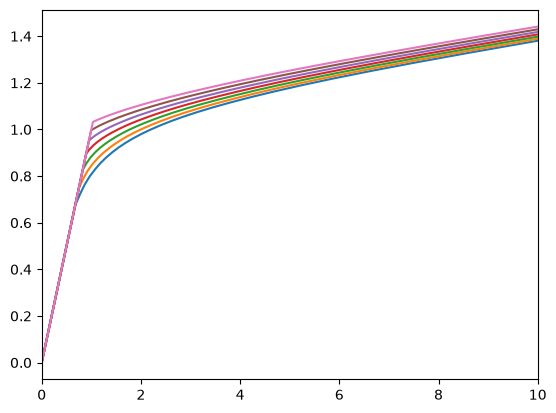

In [4]:
R = 1.03
AiyagariMarkovType.Rfree = [np.array(N * [1.03])]

# Solve and simulate the agents
AiyagariMarkovType.solve()

print("Consumption function by labor endowment level:")
plot_funcs(AiyagariMarkovType.solution[0].cFunc, 0, 10)

Calculated average normalized aggregate capital between T_sum and T: 1634.0803194370478


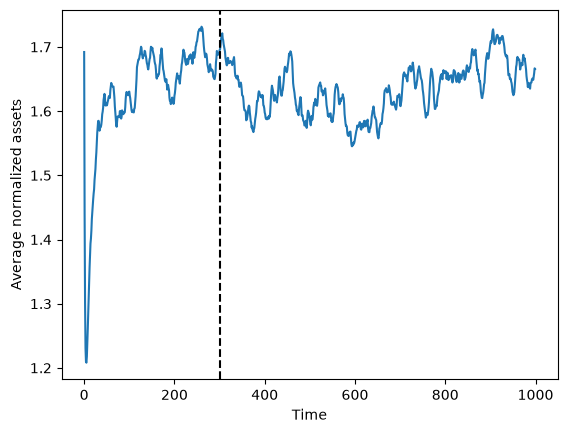

In [5]:
AverageAggregateVar = lambda var: np.mean(np.sum(var[T-T_sum:T-1], axis=1))

AiyagariMarkovType.make_shock_history()
AiyagariMarkovType.initialize_sim()
AiyagariMarkovType.simulate()
plt.plot(np.mean(AiyagariMarkovType.history["aNrm"], axis=1));
plt.axvline(x = T - T_sum, color = 'k', linestyle = 'dashed');
plt.xlabel("Time");
plt.ylabel("Average normalized assets");
print("Calculated average normalized aggregate capital between T_sum and T:", AverageAggregateVar(AiyagariMarkovType.history["aNrm"]))

Here I define useful functions for the fixed point problem. As in Aiyagari (1994), I define the capital share to be 0.36 and depreciation rate to be 0.08.

In [6]:
α = 0.36
δ = 0.08
RFunc = lambda k : 1.0 + α * k ** (α - 1.0) - δ
wFunc = lambda k: (1.0 - α) * k ** (α)
RFunc_inv = lambda R : ((R - 1.0 + δ)/α)**(1.0/(α - 1.0))

# This function takes an interest rate, simulates an economy with such an interest rate, and calculates the interest rates implied by aggregate saving. 
def CalculateImpliedR(R):
    wRte = wFunc(RFunc_inv(R))

    # Give the agents the proposed interest factor and calculate wage rate
    AiyagariMarkovType.Rfree = [np.array(N * [R])]
    
    # Solve and simulate the agents
    AiyagariMarkovType.solve()
    AiyagariMarkovType.initialize_sim()
    AiyagariMarkovType.simulate()
    
    # Extract the agents' level of assets (capital holdings) and productivity at the end
    aNrm_agg = AverageAggregateVar(AiyagariMarkovType.history["aNrm"])
    pNrm_agg = AverageAggregateVar(AiyagariMarkovType.history["TranShk"])
    
    # Calculate aggregate capital and labor and take their ratio
    K = aNrm_agg*wRte # since assets are normalized, multiply by wage rate
    L = pNrm_agg
    k = K/L
    
    # Use the rule for determining Rfree to update the interest factor
    return RFunc(k)

def EquilibriumFunc(R):
    calculated = CalculateImpliedR(R)
    print("Input R:", R, "|| Implied R:", calculated, "|| Difference", calculated - R)
    return calculated - R

Now I can solve for the equilibrium interest rate. Since consumers cannot borrow, all of the capital stock comes from their saving, and all of the demand for capital comes from firms.

Solving for the equilibrium interest rate:


In [7]:
R_star = brentq(EquilibriumFunc, 0.99, 1.05)

Input R: 0.99 || Implied R: 1.3684749796221491 || Difference 0.37847497962214915


Input R: 1.05 || Implied R: 0.9345635966454547 || Difference -0.1154364033545453


Input R: 1.035976868644877 || Implied R: 1.0827521670188212 || Difference 0.04677529837394423


Input R: 1.0400205729293608 || Implied R: 1.012215646966888 || Difference -0.02780492596247286


Input R: 1.038513003070935 || Implied R: 1.0406506699575357 || Difference 0.0021376668866006643


Input R: 1.038620631765011 || Implied R: 1.0386517196399538 || Difference 3.10878749427701e-05


Input R: 1.0386222183233766 || Implied R: 1.0386221565430627 || Difference -6.178031397574557e-08


Input R: 1.0386222151766942 || Implied R: 1.0386222151785633 || Difference 1.8691714842589136e-12


Input R: 1.0386222151776947 || Implied R: 1.0386222151599187 || Difference -1.7776002891878306e-11


In [8]:
cNrm_agg = AverageAggregateVar(AiyagariMarkovType.history["cNrm"])
aNrm_agg = AverageAggregateVar(AiyagariMarkovType.history["aNrm"])
pNrm_agg = AverageAggregateVar(AiyagariMarkovType.history["TranShk"])

income = (R_star - 1.0 + δ)*aNrm_agg + pNrm_agg

saving = (1 - cNrm_agg/income)*100   #convert to %
saving_rate = float("%.2f" % saving)  #with 2 decimals

interest = (R_star - 1)*100
interest_rate = float("%.4f" % interest)  #with 4 decimals

print("σ:", σ, "ρ:", ρ, "μ:", μ, "|| Interest rate:", interest_rate, "|| Aggregate saving rate:", saving_rate)

σ: 0.2 ρ: 0.6 μ: 3 || Interest rate: 3.8622 || Aggregate saving rate: 24.33


This result is very similar to Aiyagari (1994), who calculates the interest rate and saving rate for this combination of parameters as 3.8767 and 24.25 respectively.

### The baseline economy

The package `aiyagari1994qje`, in this repository's `src/`, packages the computation above so that other programs can use it: other documents install it from GitHub and compute the same numbers. The cells below use it to describe the baseline economy ($\sigma = 0.2$, $\rho = 0.6$, $\mu = 3$) at its equilibrium, after checking that it repeats the computation above exactly: the consumption functions, the distribution of wealth, and the supply of and demand for capital. Each figure is saved as PNG and SVG in `baseline/`, and every number, with the calibration and a definition of each, in `baseline/numbers.json`.

Quantities are in levels, for a population of mass one. The labor endowment in state $j$ is $\ell_j = \exp(x_j)$, so aggregate labor supply $L$, the population mean of $\ell$, is about 1.02 rather than 1. HARK solves the household's problem with the wage normalized to one; with wage $W$, a household with market resources $m = (1+r)a + W\ell$ consumes $W c(m/W)$, and its assets are $W$ times those of the normalized problem. Every statistic of the distribution comes from the simulation that determines the equilibrium: 1,000 households over the periods that `AverageAggregateVar` averages, pooled.

In [ ]:
from aiyagari1994qje import Calibration, solve_equilibrium
from aiyagari1994qje import plot_capital_market, plot_consumption_functions, plot_wealth_lorenz

eq = solve_equilibrium(Calibration())
assert eq.interest_factor == R_star  # the package repeats the computation above exactly

print(f"Interest rate r* = {100 * eq.interest_rate:.4f}%; time-preference rate ϑ = {100 * eq.time_preference_rate:.4f}%")
print(f"Saving rate δK/Y = {100 * eq.saving_rate_from_capital:.2f}% (1 - C/Y in the simulation: {100 * eq.saving_rate:.2f}%); "
      f"with complete markets {100 * eq.saving_rate_complete_markets:.2f}%")
print(f"Labor supply L = {eq.labor_supply:.4f}; wage W = {eq.wage:.4f}")
print(f"Capital K* = {eq.capital:.4f}, against K^ϑ = {eq.capital_complete_markets:.4f} with complete markets: "
      f"{100 * (eq.capital / eq.capital_complete_markets - 1):.2f}% more")
print(f"Wealth Gini {eq.gini:.3f}; share of wealth held by the richest 1% {100 * eq.share_of_richest(0.01):.2f}%; "
      f"share of households at the borrowing constraint {100 * eq.share_at_borrowing_constraint:.2f}%")
print(f"Average MPC {eq.average_marginal_propensity_to_consume:.4f}; perfect-foresight MPC 1 - Þ_R = {1 - eq.return_patience_factor:.4f}")

In [ ]:
os.makedirs("baseline", exist_ok=True)
plt.rcParams["svg.hashsalt"] = "Aiyagari1994QJE"  # fixed SVG element ids, so reruns write identical files

def save_figure(fig, name):
    # No timestamps or version stamps, so an unchanged figure is an unchanged file
    fig.savefig(f"baseline/{name}.png", dpi=200, bbox_inches="tight", metadata={"Software": None})
    fig.savefig(f"baseline/{name}.svg", bbox_inches="tight", metadata={"Creator": None, "Date": None})

**Consumption functions.** One for each labor endowment state, at the equilibrium interest rate. Below a kink, households consume all their market resources: they would like to borrow and cannot.

In [ ]:
fig, ax = plt.subplots(figsize=(6.4, 4.8))
plot_consumption_functions(eq, ax)
save_figure(fig, "consumption-functions")
plt.show()

**The distribution of wealth.** The Lorenz curve of end-of-period assets, with the U.S. wealth shares that Krusell and Smith (1998, Table 1) report for the richest 1, 5, 10, 20 and 30 percent of households. Idiosyncratic labor income risk alone produces far less wealth inequality than the data show.

In [ ]:
fig, ax = plt.subplots(figsize=(5, 5))
plot_wealth_lorenz(eq, ax)
save_figure(fig, "wealth-lorenz")
plt.show()

**Supply of and demand for capital.** Households supply capital by saving: at each interest rate, the supply is their average assets in the simulation. Firms demand capital until its marginal product net of depreciation equals the interest rate. As the interest rate approaches the time-preference rate $\vartheta = 1/\beta - 1$, the supply grows without limit; with complete markets the economy would settle at $r = \vartheta$ with capital $K^\vartheta$. Uninsurable risk makes households save more, so the equilibrium has more capital, $K^* > K^\vartheta$, at a lower interest rate.

In [ ]:
fig, ax = plt.subplots(figsize=(6.4, 4.8))
plot_capital_market(eq, ax)  # solves and simulates the economy at 48 interest rates
save_figure(fig, "capital-supply-demand")
plt.show()

**The numbers.** Everything above, with the calibration and a definition of each number, goes to `baseline/numbers.json`. Values are rounded to six significant digits.

In [ ]:
numbers = eq.numbers()
numbers["figures"] = {
    "consumption-functions": "Consumption c against market resources m, one line per labor endowment state, at r*, "
                             "with the 45-degree line",
    "wealth-lorenz": "Lorenz curve of wealth, with the U.S. shares of the richest 1, 5, 10, 20 and 30 percent "
                     "(Krusell and Smith 1998, Table 1)",
    "capital-supply-demand": "Supply of capital (households' average assets) and demand for capital against the interest rate "
                             "in percent, the complete-markets line at the time-preference rate, and K* and K^ϑ marked",
}
with open("baseline/numbers.json", "w") as f:
    json.dump(numbers, f, indent=2, ensure_ascii=False)
    f.write("\n")
print(json.dumps({k: numbers[k] for k in ("equilibrium", "complete_markets", "wealth_distribution")}, indent=2, ensure_ascii=False))

Now to solve for equilibrium interest rates for all combinations of parameters:

In [15]:
σ_values = [0.2, 0.4]
ρ_values = [0.0, 0.3, 0.6, 0.9]
μ_values = [1, 3, 5]
results = []

index = 0
for σ in σ_values:  
    for ρ in ρ_values:
        for μ in μ_values:
            incomes, transition_matrix = make_tauchen_ar1(N, shock_sd(ρ, σ), ρ, 3)

            AiyagariMarkovAgentDictionaryCopy = deepcopy(AiyagariMarkovAgentDictionary)
            AiyagariMarkovAgentDictionaryCopy["CRRA"] = μ
            AiyagariMarkovAgentDictionaryCopy["MrkvArray"] = [transition_matrix]
            AiyagariMarkovAgentDictionaryCopy["IncShkDstn"] = [
                [DiscreteDistributionLabeled(pmv=np.ones(1), atoms=np.array([[1.0], [np.exp(x)]]), var_names=["PermShk", "TranShk"]) for x in incomes]
            ]

            AiyagariMarkovType = MarkovConsumerType(**AiyagariMarkovAgentDictionaryCopy)
            AiyagariMarkovType.T_sim = T
            AiyagariMarkovType.track_vars = ["aNrm", "cNrm", "TranShk"]

            print("σ:", σ, "ρ:", ρ, "μ:", μ)
            t = time.process_time()
            AiyagariMarkovType.make_shock_history()
            print("Time to generate shock history:", time.process_time() - t)

            R_star = brentq(EquilibriumFunc, 0.99, 1.05)

            cNrm_agg = AverageAggregateVar(AiyagariMarkovType.history["cNrm"])
            aNrm_agg = AverageAggregateVar(AiyagariMarkovType.history["aNrm"])
            pNrm_agg = AverageAggregateVar(AiyagariMarkovType.history["TranShk"])

            income = (R_star - 1.0 + δ)*aNrm_agg + pNrm_agg

            saving = (1 - cNrm_agg/income)*100   #convert to %
            saving_rate = float("%.2f" % saving)  #with 2 decimals

            interest = (R_star - 1)*100
            interest_rate = float("%.4f" % interest)  #with 4 decimals

            results.append([saving_rate, interest_rate])
            index = index + 1

            print("σ:", σ, "ρ:", ρ, "μ:", μ, "|| Interest rate:", interest_rate, "|| Aggregate saving rate:", saving_rate)
            print("")


σ: 0.2 ρ: 0.0 μ: 1


Time to generate shock history: 3.828915000000002


Input R: 0.99 || Implied R: 1.9837698242432893 || Difference 0.9937698242432893


Input R: 1.05 || Implied R: 0.920854202334329 || Difference -0.12914579766567102


Input R: 1.043099438899276 || Implied R: 0.9499624293592571 || Difference -0.09313700954001891


...

Input R: 0.9985399973174669 || Implied R: 0.9984846848917922 || Difference -5.5312425674691745e-05


Input R: 0.9985122180991999 || Implied R: 0.9985125166900756 || Difference 2.9859087569139575e-07


Input R: 0.9985123672534795 || Implied R: 0.998512367294376 || Difference 4.0896508401999654e-11


Input R: 0.9985123672739111 || Implied R: 0.9985123672739112 || Difference 1.1102230246251565e-16


Input R: 0.9985123672749115 || Implied R: 0.9985123672729092 || Difference -2.0023982472139323e-12
σ: 0.4 ρ: 0.9 μ: 5 || Interest rate: -0.1488 || Aggregate saving rate: 36.7



In [16]:
aiyagari = [[23.67, 4.1666], [23.71, 4.1456], [23.83, 4.0858], [23.73, 4.1365], [23.91, 4.0432], [24.19, 3.9054], [23.82, 4.0912], [24.25, 3.8767], [24.86, 3.5857], [24.14, 3.9305], [25.51, 3.2903], [27.36, 2.5260], [23.87, 4.0649], [24.44, 3.7816], [25.22, 3.4177], [24.09, 3.9554], [25.22, 3.4188], [26.66, 2.8032], [24.5, 3.7567], [26.71, 2.7835], [29.37, 1.807], [25.47, 3.3054], [31.0, 1.2894], [37.63, -0.3456]]

conv = lambda x, y, xd, yd: ("%."+str(xd)+"f") % x + "/" + ("%."+str(yd)+"f") % y

row_names = {
    0:'ρ = 0',
    1:'ρ = 0.3',
    2:'ρ = 0.6',
    3:'ρ = 0.9'
}

def OutputTables(title, subtitle, operation_func, xd = 4, yd = 2):
    index = 0
    print(title)
    for sigma in range(1, 3):
        output = []
        for rho in range(1, 5):
            output_slice = []
            for theta in range(1, 4):
                r1, r2 = operation_func(results[index][0], results[index][1], aiyagari[index][0], aiyagari[index][1])
                if not r2 is None:
                    output_slice.append(conv(r1, r2, xd, yd))
                else:
                    output_slice.append(str(r1))
                index = index + 1
            output.append(output_slice)
        df = pd.DataFrame(output, columns=["µ = 1", "µ = 3", "µ = 5"])
        df = df.rename(index = row_names)
        print(subtitle + " (σ = " + str(0.2*sigma) + ")")
        print(df)
    print("\n")

def aiyagari_only(agg_s, r, A_agg_s, A_r):
    return A_r, A_agg_s

def results_only(agg_s, r, A_agg_s, A_r):
    return r, agg_s

OutputTables("Table II, Aiyagari (1994)", "Net return to capital in % / aggregate saving rate in %", aiyagari_only)
OutputTables("Table II, Replication (HARK)", "Net return to capital in % / aggregate saving rate in %", results_only)

def differences(agg_s, r, A_agg_s, A_r):
    return r - A_r, agg_s - A_agg_s

OutputTables("HARK minus Aiyagari (1994)", "Net return to capital in % / aggregate saving rate in %", differences)

Table II, Aiyagari (1994)
Net return to capital in % / aggregate saving rate in % (σ = 0.2)
                µ = 1         µ = 3         µ = 5
ρ = 0    4.1666/23.67  4.1456/23.71  4.0858/23.83
ρ = 0.3  4.1365/23.73  4.0432/23.91  3.9054/24.19
ρ = 0.6  4.0912/23.82  3.8767/24.25  3.5857/24.86
ρ = 0.9  3.9305/24.14  3.2903/25.51  2.5260/27.36
Net return to capital in % / aggregate saving rate in % (σ = 0.4)
                µ = 1         µ = 3          µ = 5
ρ = 0    4.0649/23.87  3.7816/24.44   3.4177/25.22
ρ = 0.3  3.9554/24.09  3.4188/25.22   2.8032/26.66
ρ = 0.6  3.7567/24.50  2.7835/26.71   1.8070/29.37
ρ = 0.9  3.3054/25.47  1.2894/31.00  -0.3456/37.63


Table II, Replication (HARK)
Net return to capital in % / aggregate saving rate in % (σ = 0.2)
                µ = 1         µ = 3         µ = 5
ρ = 0    4.1543/23.85  4.1111/23.92  4.0445/24.04
ρ = 0.3  4.1318/23.85  4.0304/24.04  3.8912/24.31
ρ = 0.6  4.0849/23.89  3.8622/24.33  3.5775/24.92
ρ = 0.9  3.9469/24.15  3.3405/25.43  2.6